In [18]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

WORKBOOK_PATH = Path(r"C:\Pasta_do_Jota\TCC\Estufa convecção - Borra de café.xlsx")
BED_DEPTH_M = 0.005
AIR_TEMPERATURE_K = 273.15 + 70
TIME_SCALE_S = 240.0 * 60.0
DIAMETER_REFERENCE_M = 450e-6
SPEED_REFERENCE_M_S = 0.22
DTYPE = torch.float64

if not WORKBOOK_PATH.is_file():
    raise FileNotFoundError(f"Workbook not found: {WORKBOOK_PATH}")
print(f"PyTorch {torch.__version__}; source: {WORKBOOK_PATH.name}")

PyTorch 2.10.0+cpu; source: Estufa convecção - Borra de café.xlsx


In [19]:
def parse_drying_workbook(
    sheets: dict[str, pd.DataFrame],
) -> tuple[pd.DataFrame, pd.DataFrame]:
    experiment_records = []
    observation_records = []
    expected_headers = ["borra +B", "m borra", "u", "adm", "tx"]
    for sheet_name, raw in sheets.items():
        speed_match = re.fullmatch(r"(\d+(?:[.,]\d+)?)ms", sheet_name.strip())
        if speed_match is None:
            raise ValueError(f"Unrecognized air-speed sheet: {sheet_name}")
        speed = float(speed_match.group(1).replace(",", "."))
        if speed <= 0:
            raise ValueError("Air speed must be positive.")
        labels = raw.iloc[:, 0].astype(str).str.strip()
        header_rows = raw.index[labels.eq("Tempo")].tolist()
        dry_rows = raw.index[labels.eq("Mseca")].tolist()
        if len(header_rows) != 1 or len(dry_rows) != 1:
            raise ValueError(f"Expected one Tempo and one Mseca row in {sheet_name}.")
        header_row, dry_row = header_rows[0], dry_rows[0]
        if header_row < 4 or dry_row <= header_row:
            raise ValueError(f"Invalid header/dry-mass layout in {sheet_name}.")
        numeric_time = pd.to_numeric(raw.iloc[:, 0], errors="coerce")
        time_rows = raw.index[
            (raw.index > header_row) & (raw.index < dry_row) & numeric_time.notna()
        ]
        times_min = numeric_time.loc[time_rows].to_numpy(dtype=float)
        if (
            not len(times_min)
            or not np.isfinite(times_min).all()
            or (times_min < 0).any()
        ):
            raise ValueError(f"Invalid measurement times in {sheet_name}.")
        if (
            len(np.unique(times_min)) != len(times_min)
            or not (np.diff(times_min) > 0).all()
        ):
            raise ValueError(f"Times must be unique and increasing in {sheet_name}.")
        diameter_m = None
        for start in range(1, raw.shape[1], 5):
            if start + 4 >= raw.shape[1]:
                raise ValueError(f"Incomplete sample block in {sheet_name}.")
            headers = (
                raw.iloc[header_row, start : start + 5].astype(str).str.strip().tolist()
            )
            if headers != expected_headers:
                raise ValueError(
                    f"Unexpected sample headers in {sheet_name}: {headers}"
                )
            diameter_label = raw.iloc[header_row - 4, start]
            if pd.notna(diameter_label):
                match = re.fullmatch(
                    r"(\d+(?:[.,]\d+)?)\s*(?:um|µm|μm)", str(diameter_label).strip()
                )
                if match is None:
                    raise ValueError(f"Invalid diameter label: {diameter_label}")
                diameter_m = float(match.group(1).replace(",", ".")) * 1e-6
            if diameter_m is None or diameter_m <= 0:
                raise ValueError("Each sample must have a positive diameter.")
            replicate_value = float(raw.iloc[header_row - 3, start])
            if (
                not np.isfinite(replicate_value)
                or replicate_value < 1
                or not replicate_value.is_integer()
            ):
                raise ValueError("Replicate must be a positive integer.")
            replicate = int(replicate_value)
            tare_g = float(raw.iloc[header_row - 2, start])
            dry_g = float(raw.iloc[dry_row, start + 1])
            values = raw.loc[time_rows, raw.columns[start : start + 5]].apply(
                pd.to_numeric, errors="coerce"
            )
            values.columns = [
                "total_mass_g",
                "sample_mass_g",
                "u_source",
                "adm_source",
                "tx_source",
            ]
            initial_positions = np.flatnonzero(times_min == 0)
            if len(initial_positions) != 1:
                raise ValueError("Every curve needs a measurement at t=0.")
            initial_g = float(values.iloc[initial_positions[0]]["sample_mass_g"])
            if (
                not np.isfinite([tare_g, dry_g, initial_g]).all()
                or tare_g < 0
                or not 0 < dry_g < initial_g
            ):
                raise ValueError(
                    f"Invalid tare, dry or initial mass in {sheet_name}, block {start}."
                )
            initial_u = (initial_g - dry_g) / initial_g
            condition_id = f"v{speed:g}_d{diameter_m * 1e6:g}"
            experiment_id = f"{condition_id}_r{replicate}"
            experiment_records.append(
                {
                    "experiment_id": experiment_id,
                    "condition_id": condition_id,
                    "replicate": replicate,
                    "particle_diameter_m": diameter_m,
                    "air_speed_m_s": speed,
                    "bed_depth_m": BED_DEPTH_M,
                    "air_temperature_K": AIR_TEMPERATURE_K,
                    "tare_mass_kg": tare_g / 1000,
                    "dry_mass_kg": dry_g / 1000,
                    "initial_sample_mass_kg": initial_g / 1000,
                    "initial_u": initial_u,
                    "ms_source_g": raw.iloc[header_row - 1, start],
                    "source_sheet": sheet_name,
                }
            )
            previous_mass = None
            for position, (source_index, row) in enumerate(values.iterrows()):
                mass_g = float(row["sample_mass_g"])
                total_g = float(row["total_mass_g"])
                valid_mass = np.isfinite(mass_g) and mass_g >= dry_g
                u = (mass_g - dry_g) / initial_g if np.isfinite(mass_g) else np.nan
                adm = u / initial_u
                flags = []
                if not np.isfinite(mass_g):
                    flags.append("missing_mass")
                elif mass_g < dry_g:
                    flags.append("below_dry_mass")
                if np.isfinite(mass_g):
                    if previous_mass is not None and mass_g > previous_mass + 1e-8:
                        flags.append("mass_increase")
                    previous_mass = mass_g
                if (
                    np.isfinite(total_g)
                    and np.isfinite(mass_g)
                    and not np.isclose(total_g - tare_g, mass_g, atol=1e-6, rtol=0)
                ):
                    flags.append("tare_mismatch")
                for source_column, computed in [("u_source", u), ("adm_source", adm)]:
                    source_value = float(row[source_column])
                    if (
                        np.isfinite(source_value)
                        and np.isfinite(computed)
                        and not np.isclose(source_value, computed, atol=1e-6, rtol=1e-5)
                    ):
                        flags.append(f"{source_column}_mismatch")
                time_s = times_min[position] * 60
                legacy_tx = (
                    adm / times_min[position] if times_min[position] > 0 else np.nan
                )
                observation_records.append(
                    {
                        "experiment_id": experiment_id,
                        "time_s": time_s,
                        "total_mass_kg": total_g / 1000,
                        "sample_mass_kg": mass_g / 1000,
                        "u_source": row["u_source"],
                        "adm_source": row["adm_source"],
                        "tx_source": row["tx_source"],
                        "u_recomputed": u,
                        "adm_recomputed": adm,
                        "legacy_adm_per_min": legacy_tx,
                        "target_available": bool(
                            valid_mass and "tare_mismatch" not in flags
                        ),
                        "quality_flags": ";".join(flags),
                        "source_row": int(source_index) + 1,
                    }
                )
    experiments = pd.DataFrame(experiment_records)
    observations = pd.DataFrame(observation_records)
    if experiments.empty or experiments["experiment_id"].duplicated().any():
        raise ValueError("Experiment IDs must be nonempty and unique.")
    if observations.duplicated(["experiment_id", "time_s"]).any():
        raise ValueError("Observation keys must be unique.")
    return experiments, observations


raw_sheets = pd.read_excel(WORKBOOK_PATH, sheet_name=None, header=None)
experiments, observations = parse_drying_workbook(raw_sheets)
training_view = observations.merge(
    experiments, on="experiment_id", validate="many_to_one"
)
print(
    f"{len(experiments)} experiments; {len(observations)} scheduled observations; "
    f"{observations['target_available'].sum()} usable moisture targets"
)
print(
    observations.loc[observations["quality_flags"].ne(""), "quality_flags"]
    .value_counts()
    .to_string()
)

24 experiments; 576 scheduled observations; 560 usable moisture targets
quality_flags
mass_increase     22
missing_mass      15
below_dry_mass     1


,experiment_id,time_s,total_mass_kg,sample_mass_kg,u_source,adm_source,tx_source,u_recomputed,adm_recomputed,legacy_adm_per_min,target_available,quality_flags,source_row
0,v0.22_d610_r1,0.0,0.022331,0.008583,0.488442,1.000000,NaN,0.488442,1.000000,NaN,True,,7
1,v0.22_d610_r1,60.0,0.022331,0.008583,0.488442,1.000000,1.000000,0.488442,1.000000,1.000000,True,,8
2,v0.22_d610_r1,120.0,0.022331,0.008583,0.488454,1.000024,0.500012,0.488454,1.000024,0.500012,True,mass_increase,9
3,v0.22_d610_r1,180.0,0.022319,0.008570,0.487009,0.997066,0.332355,0.487009,0.997066,0.332355,True,,10
4,v0.22_d610_r1,240.0,0.022274,0.008526,0.481859,0.986523,0.246631,0.481859,0.986523,0.246631,True,,11
5,v0.22_d610_r1,300.0,0.022253,0.008505,0.479412,0.981513,0.196303,0.479412,0.981513,0.196303,True,,12
6,v0.22_d610_r1,600.0,0.022091,0.008343,0.460491,0.942775,0.094277,0.460491,0.942775,0.094277,True,,13
7,v0.22_d610_r1,900.0,0.021910,0.008162,0.439390,0.899575,0.059972,0.439390,0.899575,0.059972,True,,14
8,v0.22_d610_r1,1200.0,0.021739,0.007991,0.419467,0.858785,0.042939,0.419467,0.858785,0.042939,True,,15
9,v0.22_d610_r1,1500.0,0.021573,0.007825,0.400184,0.819307,0.032772,0.400184,0.819307,0.032772,True,,16


Workbook tx agrees with adm / time_min: True


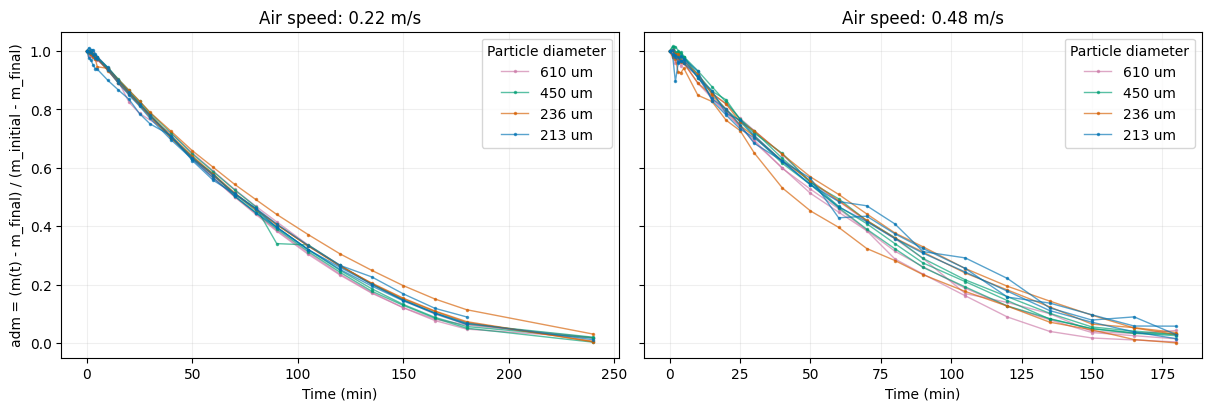

In [20]:
# display(experiments.head())
display(observations.head(10))

figure, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
colors = dict(
    zip(
        sorted(experiments["particle_diameter_m"].unique()),
        ["#0072B2", "#D55E00", "#009E73", "#CC79A7"],
    )
)
for axis, speed in zip(axes, sorted(experiments["air_speed_m_s"].unique())):
    for experiment_id, curve in training_view.loc[
        training_view["air_speed_m_s"].eq(speed)
    ].groupby("experiment_id", sort=False):
        diameter = curve["particle_diameter_m"].iloc[0]
        available = curve["target_available"]
        axis.plot(
            curve.loc[available, "time_s"] / 60,
            curve.loc[available, "adm_recomputed"],
            color=colors[diameter],
            alpha=0.65,
            linewidth=1,
            marker=".",
            markersize=3,
            label=f"{diameter * 1e6:.0f} um"
            if curve["replicate"].iloc[0] == 1
            else None,
        )
    axis.set(title=f"Air speed: {speed:g} m/s", xlabel="Time (min)")
    axis.grid(alpha=0.2)
    axis.legend(title="Particle diameter")
axes[0].set_ylabel("adm = (m(t) - m_final) / (m_initial - m_final)")
# plt.show()

legacy_pairs = observations[["tx_source", "legacy_adm_per_min"]].dropna()
print(
    "Workbook tx agrees with adm / time_min:",
    np.allclose(
        legacy_pairs["tx_source"],
        legacy_pairs["legacy_adm_per_min"],
        rtol=1e-5,
        atol=1e-6,
    ),
)

In [21]:
def make_training_tensors(frame: pd.DataFrame) -> dict[str, torch.Tensor]:
    usable = frame.loc[frame["target_available"]].copy()
    if usable.empty:
        raise ValueError("No usable moisture observations.")
    features = np.column_stack(
        [
            usable["time_s"].to_numpy() / TIME_SCALE_S,
            np.log(usable["particle_diameter_m"].to_numpy() / DIAMETER_REFERENCE_M),
            np.log(usable["air_speed_m_s"].to_numpy() / SPEED_REFERENCE_M_S),
        ]
    )
    targets = usable["adm_recomputed"].to_numpy()[:, None]
    if not np.isfinite(features).all() or not np.isfinite(targets).all():
        raise ValueError("Training features and targets must be finite.")
    curve_indices, curve_ids = pd.factorize(usable["experiment_id"], sort=True)
    counts = np.bincount(curve_indices)
    weights = 1.0 / (len(curve_ids) * counts[curve_indices])
    return {
        "features": torch.tensor(features, dtype=DTYPE),
        "adm": torch.tensor(targets, dtype=DTYPE),
        "curve_index": torch.tensor(curve_indices, dtype=torch.long),
        "weights": torch.tensor(weights[:, None], dtype=DTYPE),
    }


curve_table = experiments.sort_values("experiment_id").reset_index(drop=True)
if len(curve_table) != 24 or curve_table["experiment_id"].duplicated().any():
    raise ValueError("Expected 24 unique replicate curves for the 50/30/20 split.")
permutation = np.random.default_rng(5).permutation(len(curve_table))
split_indices = {
    "train": permutation[:12],
    "validation": permutation[12:19],
    "test": permutation[19:],
}
split_records = [
    {"experiment_id": curve_table.iloc[index]["experiment_id"], "split": split_name}
    for split_name, indices in split_indices.items()
    for index in indices
]
split_assignment = pd.DataFrame(split_records)
training_view = observations.merge(
    experiments, on="experiment_id", validate="many_to_one"
).merge(split_assignment, on="experiment_id", validate="many_to_one")
splits = {
    split_name: make_training_tensors(training_view.loc[training_view["split"].eq(split_name)])
    for split_name in split_indices
}

split_summary = (
    training_view.groupby("split")
    .agg(
        curves=("experiment_id", "nunique"),
        valid_measurements=("target_available", "sum"),
        air_speeds=("air_speed_m_s", "nunique"),
        diameters=("particle_diameter_m", "nunique"),
    )
    .reindex(["train", "validation", "test"])
)
display(split_summary)
print("Curve split proportions: 50% train, 30% validation, 20% test (seed=5).")
print("Whole replicate curves are disjoint; every split covers both speeds and all four diameters.")

,curves,valid_measurements,air_speeds,diameters
split,,,,
train,12,279,2,4
validation,7,163,2,4
test,5,118,2,4


Curve split proportions: 50% train, 30% validation, 20% test (seed=5).
Whole replicate curves are disjoint; every split covers both speeds and all four diameters.


In [22]:
class DryingPINN(nn.Module):
    def __init__(
        self, initial_diffusivity_m2_s: float, initial_surface_transfer_m_s: float
    ) -> None:
        super().__init__()
        if (
            not np.isfinite(
                [initial_diffusivity_m2_s, initial_surface_transfer_m_s]
            ).all()
            or min(initial_diffusivity_m2_s, initial_surface_transfer_m_s) <= 0
        ):
            raise ValueError(
                "Initial transport coefficients must be finite and positive."
            )
        self.network = nn.Sequential(
            nn.Linear(4, 24), nn.Tanh(), nn.Linear(24, 24), nn.Tanh(), nn.Linear(24, 1)
        ).to(dtype=DTYPE)
        self.log_diffusivity_ref = nn.Parameter(
            torch.tensor(np.log(initial_diffusivity_m2_s), dtype=DTYPE)
        )
        self.diameter_exponent = nn.Parameter(torch.zeros((), dtype=DTYPE))
        self.speed_exponent = nn.Parameter(torch.zeros((), dtype=DTYPE))
        self.log_surface_transfer_ref = nn.Parameter(
            torch.tensor(np.log(initial_surface_transfer_m_s), dtype=DTYPE)
        )
        self.surface_speed_exponent = nn.Parameter(torch.zeros((), dtype=DTYPE))

    def forward(self, coordinates: torch.Tensor) -> torch.Tensor:
        return 1.0 + coordinates[:, :1] * self.network(coordinates)

    def diffusivity(self, conditions: torch.Tensor) -> torch.Tensor:
        return torch.exp(
            self.log_diffusivity_ref
            + self.diameter_exponent * conditions[:, :1]
            + self.speed_exponent * conditions[:, 1:2]
        )

    def surface_transfer(self, conditions: torch.Tensor) -> torch.Tensor:
        return torch.exp(
            self.log_surface_transfer_ref
            + self.surface_speed_exponent * conditions[:, 1:2]
        )


def bulk_adm(
    field: nn.Module, features: torch.Tensor, n_depth: int = 16
) -> torch.Tensor:
    if n_depth < 2 or features.ndim != 2 or features.shape[1] != 3:
        raise ValueError(
            "Expected at least two depth points and features with shape (N, 3)."
        )
    depths = (
        torch.arange(n_depth, dtype=features.dtype, device=features.device) + 0.5
    ) / n_depth
    repeated = features[:, None, :].expand(-1, n_depth, -1)
    depth_column = depths[None, :, None].expand(len(features), -1, -1)
    coordinates = torch.cat(
        [repeated[:, :, :1], depth_column, repeated[:, :, 1:]], dim=2
    )
    return (
        field(coordinates.reshape(-1, 4))
        .reshape(len(features), n_depth)
        .mean(dim=1, keepdim=True)
    )


def predict_adm_and_rate(
    field: nn.Module, features: torch.Tensor
) -> tuple[torch.Tensor, torch.Tensor]:
    differentiable_features = features.detach().clone().requires_grad_(True)
    prediction = bulk_adm(field, differentiable_features)
    gradient = torch.autograd.grad(
        prediction.sum(), differentiable_features, create_graph=True
    )[0]
    return prediction, -gradient[:, :1] / TIME_SCALE_S


def coordinate_gradient(
    values: torch.Tensor, coordinates: torch.Tensor
) -> torch.Tensor:
    return torch.autograd.grad(values.sum(), coordinates, create_graph=True)[0]


def pinn_loss_terms(
    model: DryingPINN,
    batch: dict[str, torch.Tensor],
    equilibrium_adm: float,
    seed: int = 42,
    n_physics: int = 128,
) -> dict[str, torch.Tensor]:
    if (
        not np.isfinite(equilibrium_adm)
        or not 0 <= equilibrium_adm < 1
        or n_physics < 1
    ):
        raise ValueError(
            "Equilibrium adm must be in [0, 1); physics sample count must be positive."
        )
    features = batch["features"]
    generator = torch.Generator(device=features.device).manual_seed(seed)
    conditions = torch.unique(features[:, 1:], dim=0)
    selected = torch.randint(
        len(conditions), (n_physics,), generator=generator, device=features.device
    )
    sampled_conditions = conditions[selected]
    time_depth = torch.rand(
        (n_physics, 2),
        generator=generator,
        dtype=features.dtype,
        device=features.device,
    )
    interior = torch.cat([time_depth, sampled_conditions], dim=1).requires_grad_(True)
    field = model(interior)
    gradient = coordinate_gradient(field, interior)
    second_depth = coordinate_gradient(gradient[:, 1:2], interior)[:, 1:2]
    diffusivity = model.diffusivity(sampled_conditions)
    pde_residual = (
        gradient[:, :1] - diffusivity * TIME_SCALE_S / BED_DEPTH_M**2 * second_depth
    )
    base = torch.cat(
        [time_depth[:, :1], torch.zeros_like(time_depth[:, :1]), sampled_conditions],
        dim=1,
    ).requires_grad_(True)
    surface = torch.cat(
        [time_depth[:, :1], torch.ones_like(time_depth[:, :1]), sampled_conditions],
        dim=1,
    ).requires_grad_(True)
    base_gradient = coordinate_gradient(model(base), base)[:, 1:2]
    surface_field = model(surface)
    surface_gradient = coordinate_gradient(surface_field, surface)[:, 1:2]
    biot = model.surface_transfer(sampled_conditions) * BED_DEPTH_M / diffusivity
    surface_residual = surface_gradient + biot * (surface_field - equilibrium_adm)
    predicted_adm = bulk_adm(model, features)
    return {
        "data": (batch["weights"] * (predicted_adm - batch["adm"]).square()).sum(),
        "pde": pde_residual.square().mean(),
        "base_no_flux": base_gradient.square().mean(),
        "surface_flux": surface_residual.square().mean(),
        "negative_moisture": torch.relu(-field).square().mean(),
    }


torch.manual_seed(42)
model = DryingPINN(initial_diffusivity_m2_s=1e-10, initial_surface_transfer_m_s=1e-7)
loss_terms = pinn_loss_terms(model, splits["train"], equilibrium_adm=0.0)
assert all(torch.isfinite(term).item() for term in loss_terms.values())
sum(loss_terms.values()).backward()
assert (
    model.log_diffusivity_ref.grad is not None
    and torch.isfinite(model.log_diffusivity_ref.grad).item()
)
assert (
    model.log_surface_transfer_ref.grad is not None
    and torch.isfinite(model.log_surface_transfer_ref.grad).item()
)
print(
    "Untrained loss terms:",
    {name: round(term.item(), 6) for name, term in loss_terms.items()},
)
print(
    "Gradient smoke test uses training curves only; no optimizer or parameter fitting has run."
)

Untrained loss terms: {'data': 0.281243, 'pde': 0.015203, 'base_no_flux': 0.00792, 'surface_flux': 28.367755, 'negative_moisture': 0.0}
Gradient smoke test uses training curves only; no optimizer or parameter fitting has run.


In [23]:
def run_design_checks() -> None:
    assert len(experiments) == 24
    assert experiments.groupby("condition_id")["replicate"].nunique().eq(3).all()
    assert not observations.duplicated(["experiment_id", "time_s"]).any()
    assert training_view.loc[training_view["time_s"].eq(0), "adm_recomputed"].eq(1).all()
    for source, computed in [
        ("u_source", "u_recomputed"),
        ("adm_source", "adm_recomputed"),
    ]:
        paired = observations[[source, computed]].dropna()
        np.testing.assert_allclose(paired[source], paired[computed], atol=1e-6, rtol=1e-5)
    assert not observations.loc[
        observations["quality_flags"].isin(["missing_mass", "below_dry_mass"]),
        "target_available",
    ].any()
    assert observations.loc[
        observations["quality_flags"].eq("mass_increase"), "target_available"
    ].all()
    np.testing.assert_allclose(
        legacy_pairs["tx_source"],
        legacy_pairs["legacy_adm_per_min"],
        atol=1e-6,
        rtol=1e-5,
    )
    assert observations.loc[observations["time_s"].eq(0), "legacy_adm_per_min"].isna().all()

    expected_curve_counts = {"train": 12, "validation": 7, "test": 5}
    assigned_ids = {}
    for split_name, batch in splits.items():
        split_experiments = training_view.loc[training_view["split"].eq(split_name)]
        assigned_ids[split_name] = set(split_experiments["experiment_id"])
        assert split_experiments["experiment_id"].nunique() == expected_curve_counts[split_name]
        assert split_experiments["air_speed_m_s"].nunique() == 2
        assert split_experiments["particle_diameter_m"].nunique() == 4
        assert torch.isfinite(batch["features"]).all() and torch.isfinite(batch["adm"]).all()
        torch.testing.assert_close(batch["weights"].sum(), torch.tensor(1.0, dtype=DTYPE))
        n_curves = len(batch["curve_index"].unique())
        for curve_index in batch["curve_index"].unique():
            torch.testing.assert_close(
                batch["weights"][batch["curve_index"].eq(curve_index)].sum(),
                torch.tensor(1 / n_curves, dtype=DTYPE),
            )
    assert assigned_ids["train"].isdisjoint(assigned_ids["validation"])
    assert assigned_ids["train"].isdisjoint(assigned_ids["test"])
    assert assigned_ids["validation"].isdisjoint(assigned_ids["test"])
    assert sum(map(len, assigned_ids.values())) == len(experiments)

    with np.testing.assert_raises(ValueError):
        make_training_tensors(training_view.iloc[:0])
    with np.testing.assert_raises(ValueError):
        parse_drying_workbook({})
    with np.testing.assert_raises(ValueError):
        parse_drying_workbook({"invalid": next(iter(raw_sheets.values()))})
    first_sheet = next(iter(raw_sheets))
    for row_index, column_index, replacement in [
        (7, 0, 0),
        (5, 1, "unexpected"),
        (30, 2, 100),
        (1, 1, "unknown"),
    ]:
        modified = {name: frame.copy(deep=True) for name, frame in raw_sheets.items()}
        modified[first_sheet].iloc[row_index, column_index] = replacement
        with np.testing.assert_raises(ValueError):
            parse_drying_workbook(modified)
    with np.testing.assert_raises(ValueError):
        DryingPINN(0.0, 1e-7)
    with np.testing.assert_raises(ValueError):
        pinn_loss_terms(model, splits["train"], equilibrium_adm=1.0)
    with np.testing.assert_raises(ValueError):
        bulk_adm(model, splits["train"]["features"], n_depth=1)

    class ExponentialField(nn.Module):
        def forward(self, coordinates: torch.Tensor) -> torch.Tensor:
            return torch.exp(-2 * coordinates[:, :1]) + 0 * coordinates[:, 1:2].square()

    class QuadraticDepthField(nn.Module):
        def forward(self, coordinates: torch.Tensor) -> torch.Tensor:
            return coordinates[:, 1:2].square()

    analytic_features = torch.tensor(
        [[0.0, 0.0, 0.0], [0.5, 0.0, 0.0], [1.0, 0.0, 0.0]], dtype=DTYPE
    )
    analytic_adm, analytic_rate = predict_adm_and_rate(
        ExponentialField(), analytic_features
    )
    expected_adm = torch.exp(-2 * analytic_features[:, :1])
    torch.testing.assert_close(analytic_adm, expected_adm)
    torch.testing.assert_close(analytic_rate, 2 * expected_adm / TIME_SCALE_S)
    torch.testing.assert_close(
        analytic_rate * 60, 2 * expected_adm / (TIME_SCALE_S / 60)
    )
    n_depth = 64
    expected_midpoint_average = torch.full(
        (3, 1), 1 / 3 - 1 / (12 * n_depth**2), dtype=DTYPE
    )
    torch.testing.assert_close(
        bulk_adm(QuadraticDepthField(), analytic_features, n_depth),
        expected_midpoint_average,
    )

    coordinates = torch.tensor(
        [[0.2, 0.3, 0.0, 0.0], [0.7, 0.6, 0.0, 0.0]],
        dtype=DTYPE,
        requires_grad=True,
    )
    analytic_field = torch.exp(-2 * coordinates[:, :1]) * torch.cos(
        torch.pi * coordinates[:, 1:2] / 2
    )
    gradient = coordinate_gradient(analytic_field, coordinates)
    second_depth = coordinate_gradient(gradient[:, 1:2], coordinates)[:, 1:2]
    analytic_diffusivity = 2 * BED_DEPTH_M**2 / (TIME_SCALE_S * (torch.pi / 2) ** 2)
    residual = (
        gradient[:, :1]
        - analytic_diffusivity * TIME_SCALE_S / BED_DEPTH_M**2 * second_depth
    )
    torch.testing.assert_close(residual, torch.zeros_like(residual), atol=1e-12, rtol=0)
    initial_coordinates = torch.zeros((3, 4), dtype=DTYPE)
    torch.testing.assert_close(model(initial_coordinates), torch.ones((3, 1), dtype=DTYPE))
    conditions = torch.tensor([[0.0, 0.0], [-1.0, 1.0]], dtype=DTYPE)
    assert (model.diffusivity(conditions) > 0).all()
    assert (model.surface_transfer(conditions) > 0).all()
    assert all(
        parameter.grad is not None and torch.isfinite(parameter.grad).all()
        for parameter in model.parameters()
    )
    print(
        "Checks passed: data formulas, quality flags, 12/7/5 curve split, "
        "no curve leakage, rate units, PDE scaling and parameter gradients."
    )


run_design_checks()

Checks passed: data formulas, quality flags, 12/7/5 curve split, no curve leakage, rate units, PDE scaling and parameter gradients.
